Importing Libraries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy.optimize import minimize

$
P_{i} = k_{i}(n_{i})^{\Gamma_{i}}
$

In [2]:
@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

@jit(nopython=True)
def cs_from_n(mu,K,Gam,n_list):
    t1 = 1/mu
    t2 = K*Gam*((n_list)**(Gam-1))
    t = t1*t2
    return t

@jit(nopython=True)
def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

@jit(nopython=True)
def calculate_m0(energy_density, K, n, Gam):
    return (energy_density - (K * (n ** Gam)) / (Gam - 1)) / n

$
n_{0} = 0.16 fm^{-3} \\
n_{t} = [1.1,10] n_{0} \\
\Delta n = [0,9.09] n_{t}
$

In [3]:
n0 = 0.16

def ntt(z):
    return np.linspace(1.1*0.16,10*0.16,z)

def delta_nt(nt,z):
    return np.linspace(0*nt,9.09*nt,z)

$
\Gamma_{h} = [1.1,4] \\
\Gamma_{Q} = [0.5,4]
$

In [4]:
def gamm_h(z):
    return np.linspace(1.1,4,z)
def gamm_q(z):
    return np.linspace(1.1,4,z)

$
Seidov - Limit : \\
\frac{\Delta \epsilon}{\epsilon_{c}} \geq \frac{1}{2} + \frac{3}{2} \frac{P_{c}}{\epsilon_{c}}
$


In [5]:
def seidov_limit_constraint(delta_epsilon, epsilon_c, P_c):
    lhs = delta_epsilon / epsilon_c
    rhs = 0.5 + 1.5 * (P_c / epsilon_c)
    
    # Return True if lhs is greater than or equal to rhs, else False
    return lhs >= rhs

In [6]:
import itertools

def constructing_EOS(n, y):

    p, mu, e, cs = [], [], [], []
    p_c_total, mu_c_total = [], []
    gam_h, gam_q =[], []
    n_transition, delta_n = [], []
    z = n // 4
    
    gamma_h = gamm_h(z)
    gamma_q = gamm_q(z)

    nt = ntt(z)
    
    # Generate all combinations of gamma_h, gamma_q, nt, delta_n using itertools.product
    for g_h, g_q, n_t in itertools.product(gamma_h, gamma_q, nt):
        delta_n_11=[]
        #print("n")

        # Generate delta_n for each combination of n_t
        d_n_list = delta_nt(n_t, z)
        
        # Iterate over delta_n values
        for d_n in d_n_list:
            #print(d_n)
            pih = 3.542
            muih = 977.5
            eih = 1.1 * 0.16 * muih - pih
            k_had = pih / (1.1 * 0.16) ** g_h

            n_had = np.linspace(1.1 * 0.16, n_t, y)

            p_had = P_from_nb(n_had, k_had, Gam=g_h)
            m_had = calculate_m0(energy_density=eih, K=k_had, n=1.1*0.16, Gam=g_h)
            mu_had = mu_from_nb(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
            e_had = e_from_n(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
            cs_had = cs_from_n(mu=mu_had, K=k_had, Gam=g_h, n_list=n_had)

            if cs_had[-5] < 1 :

                n_mid = np.linspace(n_t, n_t + d_n, y)

                p_mid = np.linspace(p_had[-1],p_had[-1],y)
                mu_mid = np.linspace(mu_had[-1],mu_had[-1],y)
                e_mid = n_mid*mu_mid - p_mid
                cs_mid = np.gradient(p_mid,e_mid)

                delta_e = e_mid[-1] - e_mid[0]
                p_c = p_had[-1]
                mu_c = mu_had[-1]
                e_c = e_had[-1]
                truth_value = seidov_limit_constraint(delta_epsilon=delta_e, epsilon_c=e_c, P_c=p_c)
                #truth_value =True

                if truth_value == True:
                    # If the Seidov limit constraint is satisfied
                    n_iq = n_t + d_n
                    piq = p_had[-1]
                    k_quark = piq / (n_iq ** g_q)
                    m_quark = calculate_m0(energy_density=e_mid[-1], K=k_quark, n=n_iq, Gam=g_q)
                    n_fq = (1000 / k_quark) ** (1 / g_q)
                    #n_fq = 10*n0
                    n_quark = np.linspace(n_t + d_n, n_fq, y)

                    p_quark = P_from_nb(n_quark, k_quark, Gam=g_q)
                    mu_quark = mu_from_nb(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
                    e_quark = e_from_n(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
                    cs_quark = cs_from_n(mu=mu_quark, K=k_quark, Gam=g_q, n_list=n_quark)

                    p.append(np.concatenate((p_had, p_mid, p_quark)))
                    mu.append(np.concatenate((mu_had, mu_mid, mu_quark)))
                    e.append(np.concatenate((e_had, e_mid, e_quark)))
                    cs.append(np.concatenate((cs_had, cs_mid, cs_quark)))

                    gam_h.append(g_h)
                    gam_q.append(g_q)

                    n_transition.append(nt)
                    delta_n_11.append(d_n)

                    p_c_total.append(p_c)
                    mu_c_total.append(mu_c)
                delta_n.append(delta_n_11)
    # Default return if no valid result found
    return p, mu, e, cs, mu_c_total, p_c_total, gam_h, gam_q, n_transition, delta_n

In [7]:
p, mu, e, cs, mu_c_total, p_c_total, gam_h, gam_q, n_transition, delta_n = constructing_EOS(60,100)

/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1238: RuntimeWarning: invalid value encountered in divide
  out[tuple(slice1)] = (f[tuple(slice4)] - f[tuple(slice2)]) / (2. * ax_dx)
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1259: RuntimeWarning: invalid value encountered in scalar divide
  out[tuple(slice1)] = (f[tuple(slice2)] - f[tuple(slice3)]) / dx_0
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1266: RuntimeWarning: invalid value encountered in scalar divide
  out[tuple(slice1)] = (f[tuple(slice2)] - f[tuple(slice3)]) / dx_n


In [8]:
len(p)

34440

In [9]:
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = e, p, mu, cs, p_c_total, mu_c_total

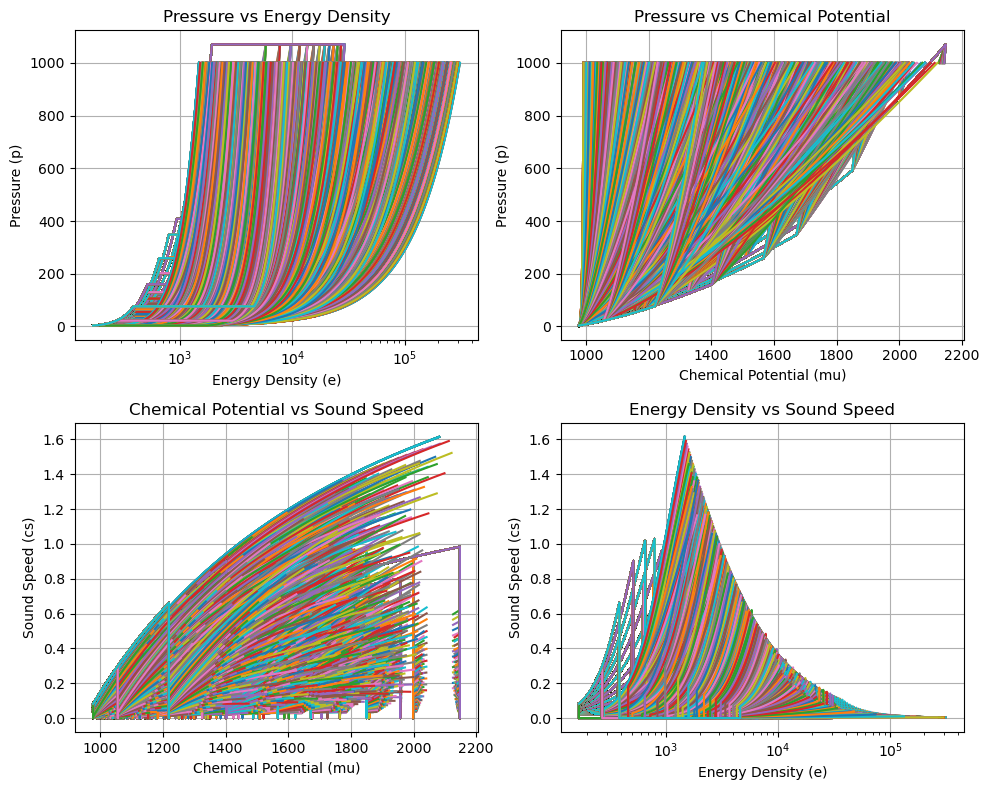

In [10]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# After the loop, plot concatenated data
for i in range(len(p)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xscale('log')
#axes[0, 0].set_yscale('log')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].set_xscale('log')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

 Relation of  Dependece od Additional Pressure term on these EOS 

In [11]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []

# Iterate through each mu_total and p_total index
for index in range(len(mu_total)):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = p_total[index][-3]
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for P in P_crit_new:
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    min_distance_points = np.array(min_distance_points)


    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index])
        P_all_1.append(P_optimal[0])
        P_max_points.append(min_distance_points[index])
        P_max_points_1.append(min_distance_points[0])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)

KeyboardInterrupt: 

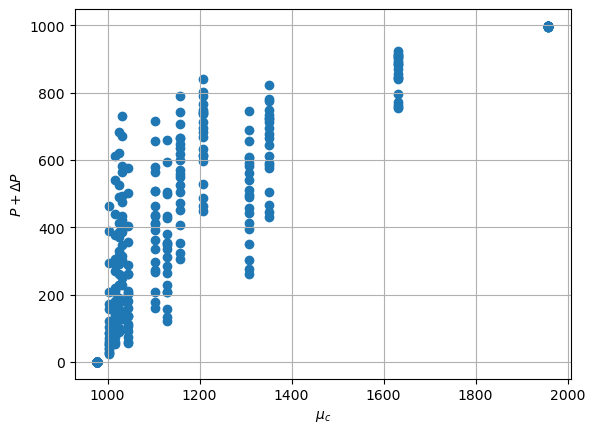

In [ ]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [13]:
for i in range(len(P_all_1)):
    if P_all_1[i] == 0 :
        print(mu_crit[i])

977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5000000000001
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.5
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.4999999999999
977.5
977.5
977.5
977.5
977.5
977.5
977.

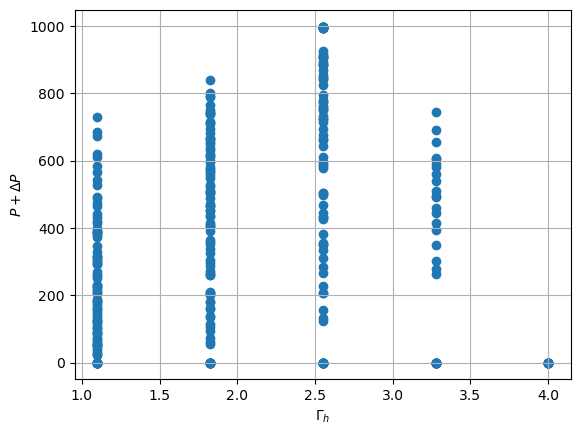

In [ ]:
plt.scatter(gam_h,P_all_1);
plt.grid();
plt.xlabel(r'$\Gamma_{h}$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

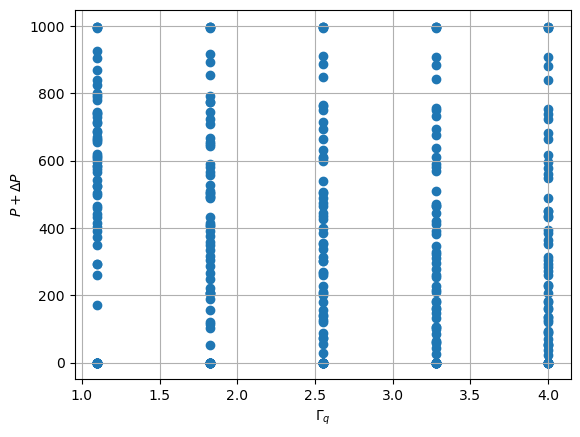

In [ ]:
plt.scatter(gam_q,P_all_1);
plt.grid();
plt.xlabel(r'$\Gamma_{q}$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [ ]:
import plotly.graph_objects as go

# Assuming `gam_h`, `gam_q`, and `P_all_1` are defined as lists or arrays
fig = go.Figure()

# Add a 3D scatter plot
fig.add_trace(go.Scatter3d(
    x=mu_crit,  # X-axis data
    y=gam_q,  # Y-axis data
    z=P_all,  # Z-axis data
    mode='markers',
    marker=dict(
        size=5,       # Marker size
        color='red',  # Marker color
        opacity=0.8   # Transparency
    ),
    name="Data Points"
))

# Update layout
fig.update_layout(
    title='3D Scatter Plot',
    scene=dict(
        xaxis_title=r'Mu_Crit',
        yaxis_title=r'Gam_q',
        zaxis_title=r'Pressure'
    ),
    margin=dict(l=0, r=0, b=0, t=40)  # Adjust margins
)

# Show the plot
fig.show()


In [17]:
# Find the unique values
unique_values = np.unique(mu_crit)
values=[]
indi=[]
# Get the indices of each unique value
indices = {val: np.where(mu_crit == val)[0] for val in unique_values}

print("Unique values and their indices:")
for val, idx in indices.items():
    values.append(val)
    indi.append(idx)
    print(f"Value: {val}, Indices: {idx}")


Unique values and their indices:
Value: 977.4999999999999, Indices: [300 301 302 303 308 309 310 311 316 317 318 319 324 325 326 327 332 333
 334 335]
Value: 977.5, Indices: [  0   1   2   3  20  21  22  23  40  41  42  43  60  61  62  63  80  81
  82  83 200 201 202 203 220 221 222 223 240 241 242 243 260 261 262 263
 280 281 282 283 340 341 342 343 344 345 346 347 348 349 350 351 352 353
 354 355 356 357 358 359]
Value: 977.5000000000001, Indices: [100 101 102 103 120 121 122 123 140 141 142 143 160 161 162 163 180 181
 182 183]
Value: 1003.3933157296582, Indices: [ 4  5  6  7 24 25 26 27 44 45 46 47 64 65 66 67 84 85 86 87]
Value: 1016.391699061443, Indices: [ 8  9 10 11 28 29 30 31 48 49 50 51 68 69 70 71 88 89 90 91]
Value: 1025.3152621780025, Indices: [12 13 14 15 32 33 34 35 52 53 54 55 72 73 74 75 92 93 94 95]
Value: 1032.175987899671, Indices: [16 17 18 19 36 37 38 39 56 57 58 59 76 77 78 79 96 97 98 99]
Value: 1043.866355290761, Indices: [104 105 106 107 124 125 126 127 144 1

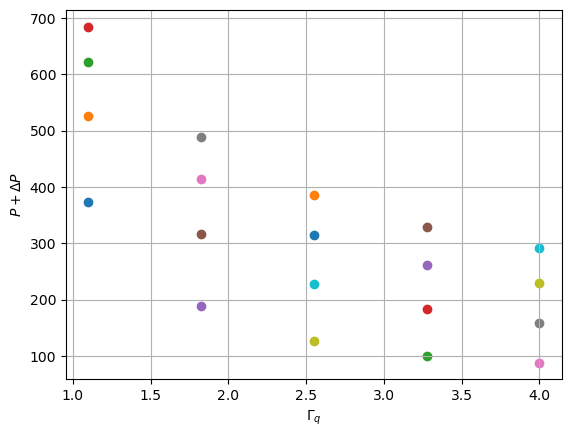

In [ ]:
for i in range(len(indi[5])):
    x=int(indi[5][i])
    plt.scatter(gam_q[x],P_all_1[x]);
    plt.xlabel(r'$\Gamma_{q}$');
    plt.ylabel(r'$P + \Delta P $');
plt.grid();
plt.show();

In [19]:
x_11,y_11,z_11=[],[],[]

for i in range(len(indi[5])):
    n=int(indi[5][i])

    x_11.append(gam_h[n])
    y_11.append(gam_q[n])
    z_11.append(P_all[n])


In [20]:
import plotly.graph_objects as go

# Assuming `gam_h`, `gam_q`, and `P_all_1` are defined as lists or arrays
fig = go.Figure()

# Add a 3D scatter plot
fig.add_trace(go.Scatter3d(
    x=x_11,  # X-axis data
    y=y_11,  # Y-axis data
    z=z_11,  # Z-axis data
    mode='markers',
    marker=dict(
        size=5,       # Marker size
        color='red',  # Marker color
        opacity=0.8   # Transparency
    ),
    name="Data Points"
))

# Update layout
fig.update_layout(
    title='3D Scatter Plot',
    scene=dict(
        xaxis_title=r'Gam_h',
        yaxis_title=r'Gam_q',
        zaxis_title=r'Pressure'
    ),
    margin=dict(l=0, r=0, b=0, t=40)  # Adjust margins
)

# Show the plot
fig.show()


In [21]:
# Find the unique values
unique_values = np.unique(delta_n)
values=[]
indi=[]
# Get the indices of each unique value
indices = {val: np.where(delta_n == val)[0] for val in unique_values}

print("Unique values and their indices:")
for val, idx in indices.items():
    values.append(val)
    indi.append(idx)
    print(f"Value: {val}, Indices: {idx}")

Unique values and their indices:
Value: 0.39996000000000004, Indices: [  0   1   2   3   4  25  26  27  28  29  50  51  52  53  54  75  76  77
  78  79 100 101 102 103 104 125 126 127 128 129 150 151 152 153 154 175
 176 177 178 179 200 201 202 203 204 225 226 227 228 229 250 251 252 253
 254 275 276 277 278 279 300 301 302 303 304 325 326 327 328 329 350 351
 352 353 354 375 376 377 378 379 385 386 387 388 389 395 396 397 398 399
 405 406 407 408 409 415 416 417 418 419 425 426 427 428 429 430 431 432
 433 434 435 436 437 438 439 440 441 442 443 444 445 446 447 448 449]
Value: 0.7999200000000001, Indices: [  0   1   2   3   4  25  26  27  28  29  50  51  52  53  54  75  76  77
  78  79 100 101 102 103 104 125 126 127 128 129 150 151 152 153 154 175
 176 177 178 179 200 201 202 203 204 225 226 227 228 229 250 251 252 253
 254 275 276 277 278 279 300 301 302 303 304 325 326 327 328 329 350 351
 352 353 354 375 376 377 378 379 385 386 387 388 389 395 396 397 398 399
 405 406 407 408 409 

In [22]:
delta_n[5]

[1.20897, 2.41794, 3.6269100000000005, 4.83588]

# For Code Verification

In [23]:
p, mu, e, cs = [], [], [], []

# Generate all combinations of gamma_h, gamma_q, nt, delta_n using itertools.product
g_h, g_q, n_t =4.921, 4.00, 0.32

#print("n")

# Generate delta_n for each combination of n_t
d_n = 0.5344-0.32
y,z =100,20

pih = 3.542
muih = 977.5
eih = 1.1 * 0.16 * muih - pih
k_had = pih / (1.1 * 0.16) ** g_h

n_had = np.linspace(1.1 * 0.16, n_t, y)

p_had = P_from_nb(n_had, k_had, Gam=g_h)
m_had = calculate_m0(energy_density=eih, K=k_had, n=1.1*0.16, Gam=g_h)
mu_had = mu_from_nb(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
e_had = e_from_n(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
cs_had = cs_from_n(mu=mu_had, K=k_had, Gam=g_h, n_list=n_had)

if cs_had[-5] < 1 :

    n_mid = np.linspace(n_t, n_t + d_n, y)

    p_mid = np.linspace(p_had[-1],p_had[-1],y)
    mu_mid = np.linspace(mu_had[-1],mu_had[-1],y)
    e_mid = n_mid*mu_mid - p_mid
    cs_mid = np.gradient(p_mid,e_mid)

    delta_e = e_mid[-1] - e_mid[0]
    p_c = p_had[-1]
    mu_c = mu_had[-1]
    e_c = e_had[-1]
    #truth_value = seidov_limit_constraint(delta_epsilon=delta_e, epsilon_c=e_c, P_c=p_c)
    truth_value =True
    print('naveen')
    if truth_value == True:
        # If the Seidov limit constraint is satisfied
        print('naveen')
        n_iq = n_t + d_n
        piq = p_had[-1]
        k_quark = piq / (n_iq ** g_q)
        m_quark = calculate_m0(energy_density=e_mid[-1], K=k_quark, n=n_iq, Gam=g_q)
        #n_fq = (3500 / k_quark) ** (1 / g_q)
        n_fq = 10*n0
        n_quark = np.linspace(n_t + d_n, n_fq, y)

        p_quark = P_from_nb(n_quark, k_quark, Gam=g_q)
        mu_quark = mu_from_nb(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
        e_quark = e_from_n(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
        cs_quark = cs_from_n(mu=mu_quark, K=k_quark, Gam=g_q, n_list=n_quark)

        p.append(np.concatenate((p_had, p_mid, p_quark)))
        mu.append(np.concatenate((mu_had, mu_mid, mu_quark)))
        e.append(np.concatenate((e_had, e_mid, e_quark)))
        cs.append(np.concatenate((cs_had, cs_mid, cs_quark)))


naveen
naveen


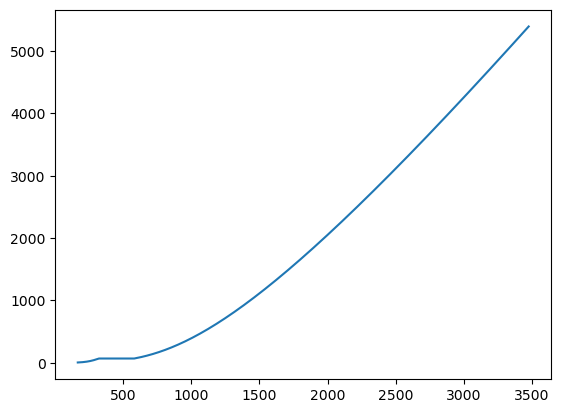

In [24]:
plt.plot(e[0],p[0])

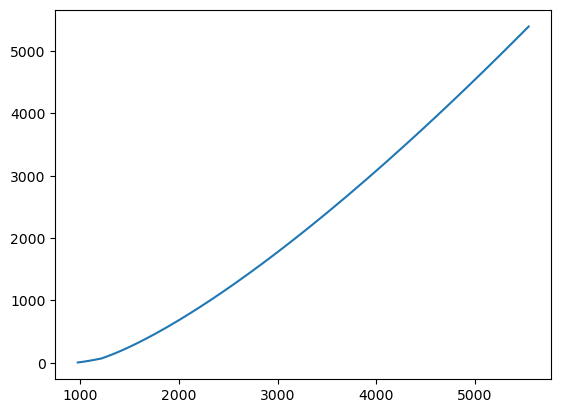

In [25]:
plt.plot(mu[0],p[0])

(0.0, 1.0)

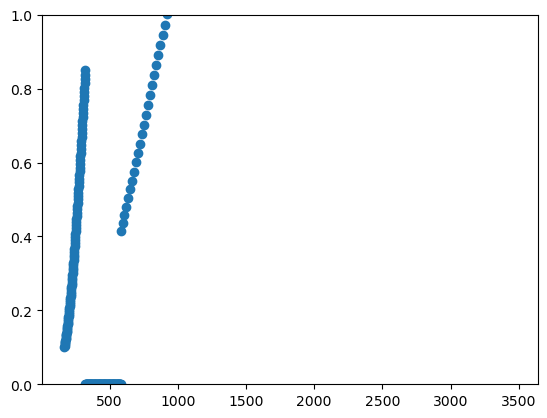

In [26]:
plt.scatter(e[0],cs[0])
#plt.xlim([800,1800])
plt.ylim([0,1])

In [27]:
seidov_limit_constraint(253.89, 318.26, 63.177)

False

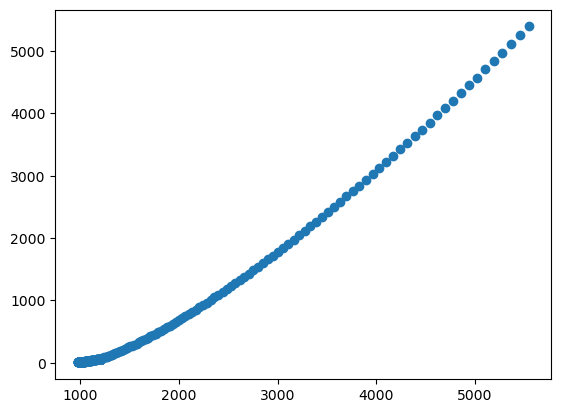

In [28]:
# Assuming e and p are lists or arrays of the same length
for i in range(len(e)):
    plt.scatter(mu[i], p[i])
    
plt.show()

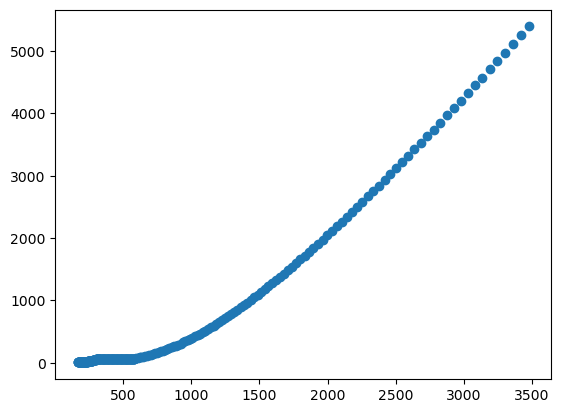

In [29]:
# Assuming e and p are lists or arrays of the same length
for i in range(len(e)):
    plt.scatter(e[i], p[i])
    
plt.show()

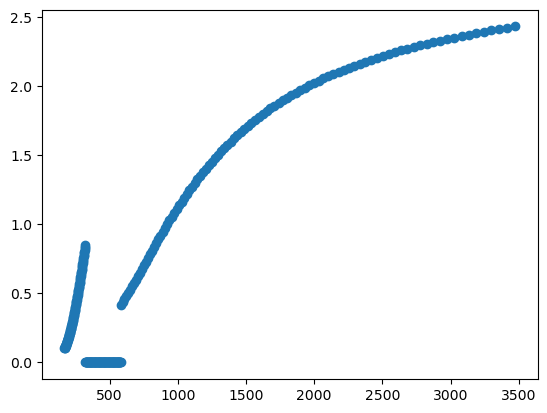

In [30]:
# Assuming e and p are lists or arrays of the same length
for i in range(len(e)):
    plt.scatter(e[i], cs[i])
plt.show()

In [31]:
plt.scatter(e[150], cs[150])

IndexError: list index out of range